| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_1_Precalculo.ipynb) | [⏩](./1_3_Calculo_integral.ipynb) |

# 1. LÍMITES

## 1.1 La idea intuitiva


El límite responde:

> ¿A qué valor se aproxima $f(x)$ cuando $(x)$ se acerca a determinado punto?

Escribimos:

$$
\lim_{x\rightarrow a}f(x)=L
$$

Significa que cuando:

$$
x\rightarrow a
$$

entonces:

$$
f(x)\rightarrow L
$$

No necesariamente necesitamos que $f(a)$ exista.

# 1.2 Ejemplo sencillo

$$
f(x)=x^2
$$

Entonces:

$$
\lim_{x\rightarrow3}x^2=9
$$

Porque:

$$
x^2\rightarrow3^2=9
$$

# 1.3 Ejemplo donde aparece una indeterminación

Considera:

$$
f(x)=\frac{x^2-9}{x-3}
$$

Si ponemos directamente $(x=3)$:

$$
\frac{9-9}{3-3}
=
\frac00
$$

Esto no significa que el límite sea $(0/0)$.

Factorizamos:

$$
x^2-9=(x-3)(x+3)
$$

Entonces:

$$
f(x)=x+3
$$

para $(x\neq3)$.

Por tanto:

$$
\boxed{
\lim_{x\rightarrow3}
\frac{x^2-9}{x-3}=6
}
$$

La función puede estar definida de forma diferente exactamente en $(x=3)$, pero el límite puede seguir existiendo.

# 1.4 Visualización con Python

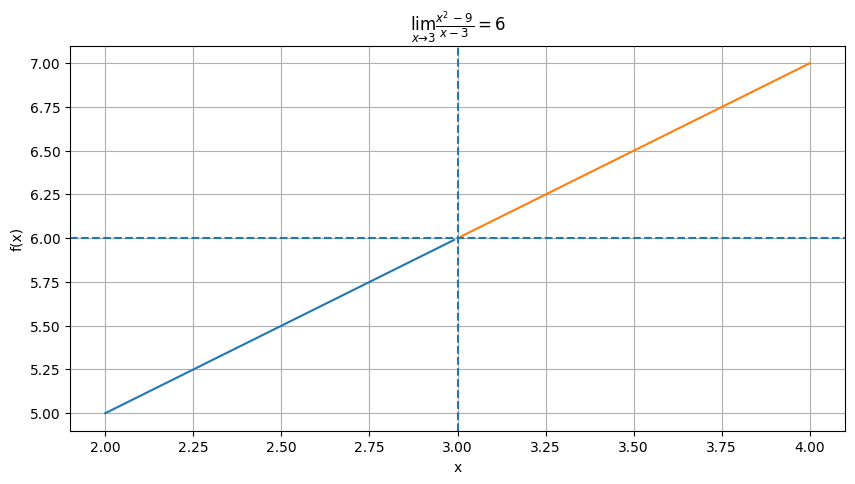

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x_left = np.linspace(2, 2.99, 500)
x_right = np.linspace(3.01, 4, 500)

f_left = (x_left**2 - 9)/(x_left - 3)
f_right = (x_right**2 - 9)/(x_right - 3)

plt.figure(figsize=(10, 5))

plt.plot(x_left, f_left)
plt.plot(x_right, f_right)

plt.scatter([3], [6], facecolors="none", s=100)

plt.axvline(3, linestyle="--")
plt.axhline(6, linestyle="--")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(r"$\lim_{x\to3}\frac{x^2-9}{x-3}=6$")
plt.grid(True)

plt.show()

La gráfica muestra que la función se acerca a:

$$
6
$$

aunque el punto $(x=3)$ tenga un problema.

# 1.5 Ejemplo difícil: límite trigonométrico

Uno de los límites fundamentales es:

$$
\boxed{
\lim_{x\rightarrow0}
\frac{\sin x}{x}=1
}
$$

Esto es importantísimo porque aparecerá posteriormente al demostrar derivadas de funciones trigonométricas.

Podemos comprobarlo numéricamente:

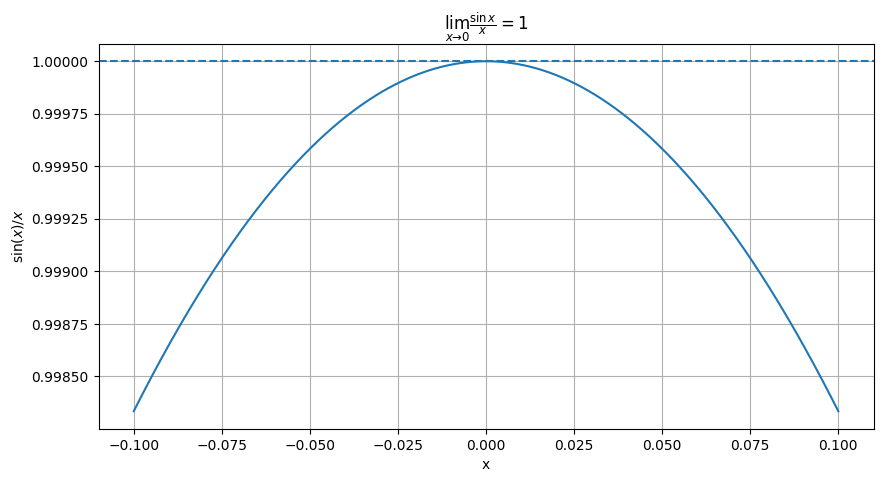

In [2]:
x = np.linspace(-0.1, 0.1, 2000)

y = np.sin(x)/x

plt.figure(figsize=(10, 5))
plt.plot(x, y)
plt.axhline(1, linestyle="--")

plt.xlabel("x")
plt.ylabel(r"$\sin(x)/x$")
plt.title(r"$\lim_{x\to0}\frac{\sin x}{x}=1$")
plt.grid(True)

plt.show()

# 1.6 ¿Para qué sirve en la vida real?

Imagina que tienes:

$$
s(t)
$$

como posición de un vehículo.

Para calcular su velocidad instantánea usamos:

$$
v(t)=
\lim_{\Delta t\rightarrow0}
\frac{s(t+\Delta t)-s(t)}
{\Delta t}
$$

Es decir:

> **la derivada nace del límite.**

# 2. CONTINUIDAD

Una función es continua en $(x=a)$ si se cumplen tres condiciones:

### 1.

$$
f(a)
$$

existe.

### 2.

$$
\lim_{x\rightarrow a}f(x)
$$

existe.

### 3.

$$
\boxed{
\lim_{x\rightarrow a}f(x)=f(a)
}
$$

# 2.1 Ejemplo

$$
f(x)=x^2+2x+1
$$

es continua para todos los reales.

Pero considera:

$$
f(x)=
\begin{cases}
x^2 & x\neq2\\
10 & x=2
\end{cases}
$$

El límite es:

$$
\lim_{x\rightarrow2}x^2=4
$$

pero:

$$
f(2)=10
$$

Por tanto:

$$
\boxed{\text{no es continua en }x=2}
$$

# 2.2 Python

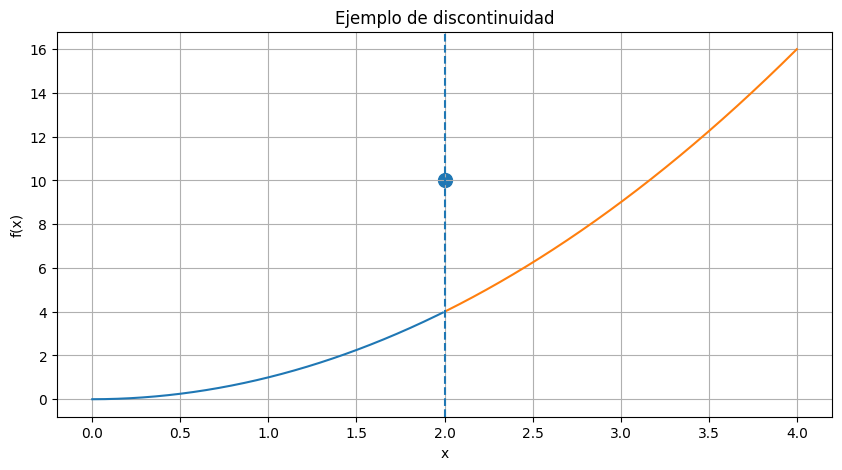

In [3]:
x1 = np.linspace(0, 1.99, 500)
x2 = np.linspace(2.01, 4, 500)

y1 = x1**2
y2 = x2**2

plt.figure(figsize=(10, 5))

plt.plot(x1, y1)
plt.plot(x2, y2)

plt.scatter([2], [4], facecolors="none", s=100)
plt.scatter([2], [10], s=100)

plt.axvline(2, linestyle="--")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Ejemplo de discontinuidad")
plt.grid(True)

plt.show()

# 2.3 ¿Por qué importa para SciML?

Muchos modelos físicos suponen que una magnitud cambia suavemente.

Por ejemplo:

$$
T(x,t)
$$

temperatura.

Si introduces discontinuidades, pueden aparecer problemas numéricos.

Pero cuidado:

> **Las discontinuidades también existen físicamente.**

Por ejemplo:

* choque de un fluido;
* cambios bruscos de material;
* señales digitales;
* interfaces.

Por eso SciML necesita conocer muy bien continuidad y regularidad.

# 3. DERIVADAS

Ahora llegamos al corazón del cálculo diferencial.

La derivada mide:

$$
\boxed{\text{tasa de cambio instantánea}}
$$

Formalmente:

$$
\boxed{
f'(x)=
\lim_{h\rightarrow0}
\frac{f(x+h)-f(x)}{h}
}
$$

# 3.1 Ejemplo

$$
f(x)=x^2
$$

Aplicamos la definición:

$$
f'(x)
=
\lim_{h\rightarrow0}
\frac{(x+h)^2-x^2}{h}
$$

Expandimos:

$$
=
\lim_{h\rightarrow0}
\frac{x^2+2xh+h^2-x^2}{h}
$$

$$
=
\lim_{h\rightarrow0}
\frac{2xh+h^2}{h}
$$

$$
=
\lim_{h\rightarrow0}(2x+h)
$$

Por tanto:

$$
\boxed{f'(x)=2x}
$$

# 3.2 Ejemplo difícil

Considera:

$$
f(x)=e^{-x^2}\sin(3x)
$$

Usamos la regla del producto.

Sea:

$$
u=e^{-x^2}
$$

$$
v=\sin(3x)
$$

Entonces:

$$
u'=-2xe^{-x^2}
$$

y:

$$
v'=3\cos(3x)
$$

Por tanto:

$$
f'(x)
=
-2xe^{-x^2}\sin(3x)
+
3e^{-x^2}\cos(3x)
$$

Factorizando:

$$
\boxed{
f'(x)=
e^{-x^2}
\left[
3\cos(3x)-2x\sin(3x)
\right]
}
$$

# 3.3 Graficar función y derivada

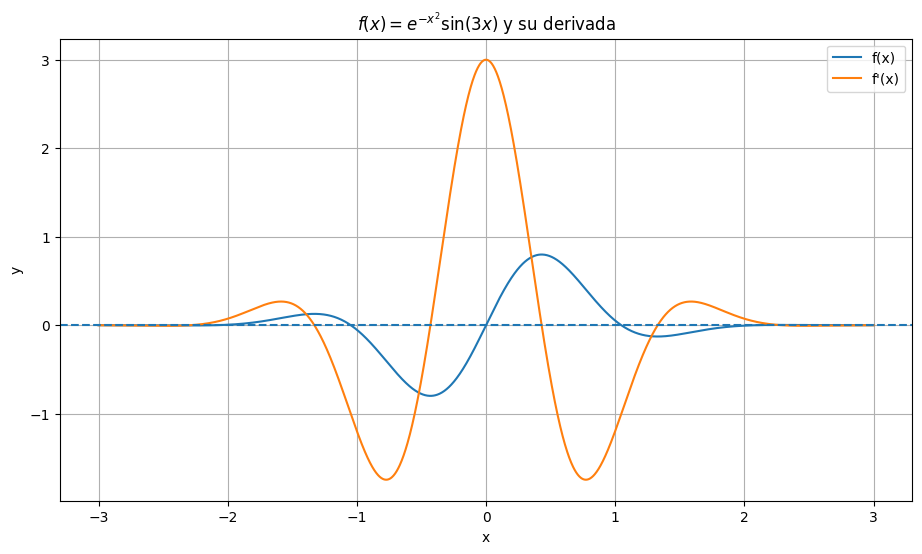

In [4]:
x = np.linspace(-3, 3, 2000)

f = np.exp(-x**2)*np.sin(3*x)

df = np.exp(-x**2)*(3*np.cos(3*x) - 2*x*np.sin(3*x))

plt.figure(figsize=(11, 6))

plt.plot(x, f, label="f(x)")
plt.plot(x, df, label="f'(x)")

plt.axhline(0, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$f(x)=e^{-x^2}\sin(3x)$ y su derivada")
plt.grid(True)
plt.legend()

plt.show()

# 4. INTERPRETACIÓN GEOMÉTRICA

La derivada tiene una interpretación geométrica muy importante:

$$
\boxed{f'(a)=\text{pendiente de la recta tangente en }a}
$$

# 4.1 Secante → tangente

La pendiente de una secante:

$$
m=
\frac{f(a+h)-f(a)}{h}
$$

Cuando:

$$
h\rightarrow0
$$

la secante se convierte en tangente.

# 4.2 Ejemplo

Consideremos:

$$
f(x)=x^2
$$

en:

$$
x=2
$$

Tenemos:

$$
f'(2)=4
$$

La recta tangente:

$$
y-f(2)=f'(2)(x-2)
$$

Como:

$$
f(2)=4
$$

entonces:

$$
y-4=4(x-2)
$$

$$
\boxed{y=4x-4}
$$

# 4.3 Python

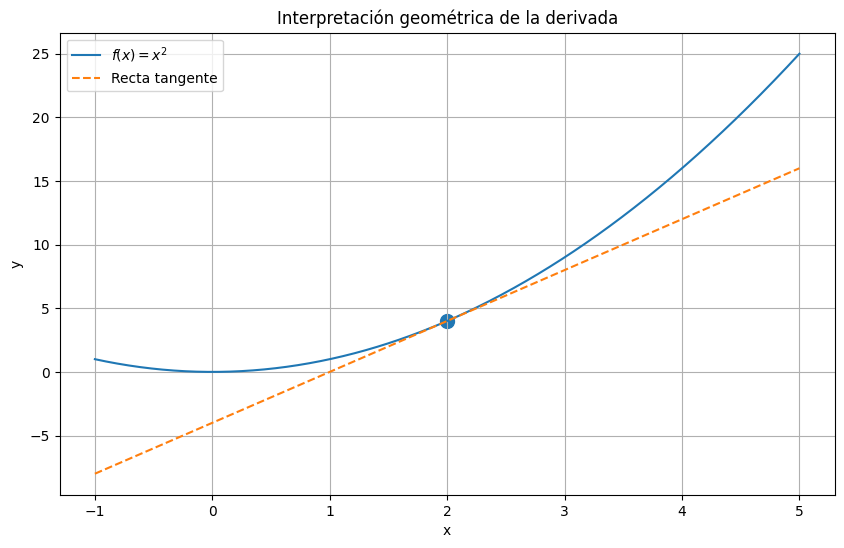

In [5]:
x = np.linspace(-1, 5, 1000)

f = x**2
tangent = 4*x - 4

plt.figure(figsize=(10, 6))

plt.plot(x, f, label=r"$f(x)=x^2$")
plt.plot(x, tangent, linestyle="--", label="Recta tangente")

plt.scatter([2], [4], s=100)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpretación geométrica de la derivada")
plt.grid(True)
plt.legend()

plt.show()

# 4.4 Aplicación: velocidad

Si:

$$
s(t)
$$

es posición, entonces:

$$
s'(t)=v(t)
$$

Y:

$$
s''(t)=a(t)
$$

Por ejemplo:

$$
s(t)=t^3-6t^2+9t
$$

Entonces:

$$
v(t)=3t^2-12t+9
$$

y:

$$
a(t)=6t-12
$$

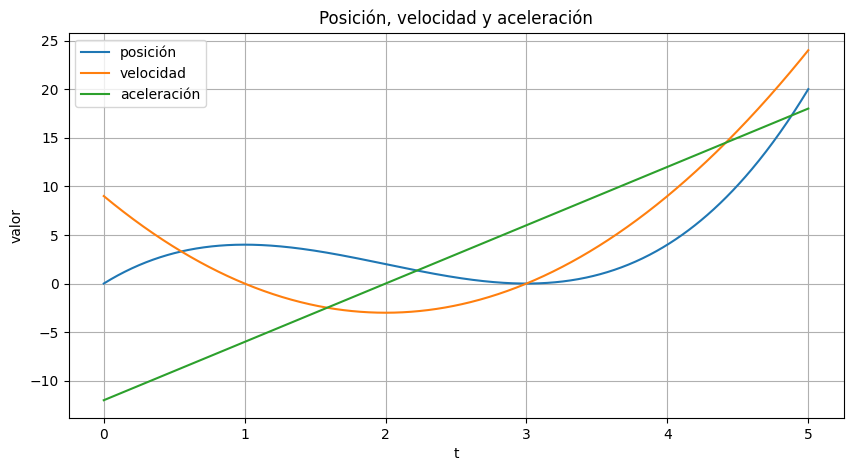

In [6]:
t = np.linspace(0, 5, 1000)

s = t**3 - 6*t**2 + 9*t
v = 3*t**2 - 12*t + 9
a = 6*t - 12

plt.figure(figsize=(10, 5))
plt.plot(t, s, label="posición")
plt.plot(t, v, label="velocidad")
plt.plot(t, a, label="aceleración")

plt.xlabel("t")
plt.ylabel("valor")
plt.title("Posición, velocidad y aceleración")
plt.grid(True)
plt.legend()

plt.show()

# 5. REGLA DE LA CADENA

Esta es **fundamental para Machine Learning**.

Si:

$$
y=f(g(x))
$$

entonces:

$$
\boxed{
\frac{dy}{dx}
=
f'(g(x))g'(x)
}
$$

# 5.1 Ejemplo

$$
y=e^{\sin(x^2)}
$$

Tenemos varias capas.

Primero:

$$
u=x^2
$$

Después:

$$
v=\sin u
$$

Finalmente:

$$
y=e^v
$$

Aplicamos cadena:

$$
\frac{dy}{dx}
=
e^{\sin(x^2)}
\cos(x^2)
(2x)
$$

Por tanto:

$$
\boxed{
y'=2xe^{\sin(x^2)}\cos(x^2)
}
$$

# 5.2 ¿Por qué esto es fundamental para Machine Learning?

Una red neuronal es esencialmente una composición:

$$
f(x)=f_3(f_2(f_1(x)))
$$

La regla de la cadena permite calcular:

$$
\frac{\partial L}{\partial w}
$$

donde $(L)$ es la función de pérdida.

Esto es la base matemática del **backpropagation**.

Conceptualmente:

$$
x
\rightarrow
f_1
\rightarrow
f_2
\rightarrow
f_3
\rightarrow
L
$$

y la derivada retrocede:

$$
\frac{\partial L}{\partial f_3}
\frac{\partial f_3}{\partial f_2}
\frac{\partial f_2}{\partial f_1}
\frac{\partial f_1}{\partial x}
$$

La regla de la cadena que estás aprendiendo ahora es uno de los fundamentos matemáticos de las redes neuronales.

# 6. DERIVACIÓN IMPLÍCITA

No siempre tenemos:

$$
y=f(x)
$$

A veces tenemos una ecuación:

$$
F(x,y)=0
$$

y necesitamos:

$$
\frac{dy}{dx}
$$

# 6.1 Ejemplo

Consideremos:

$$
x^2+y^2=25
$$

Derivamos ambos lados respecto de $(x)$:

$$
2x+2y\frac{dy}{dx}=0
$$

Entonces:

$$
2y\frac{dy}{dx}=-2x
$$

$$
\boxed{
\frac{dy}{dx}=-\frac{x}{y}
}
$$

# 6.2 Python: círculo y tangente

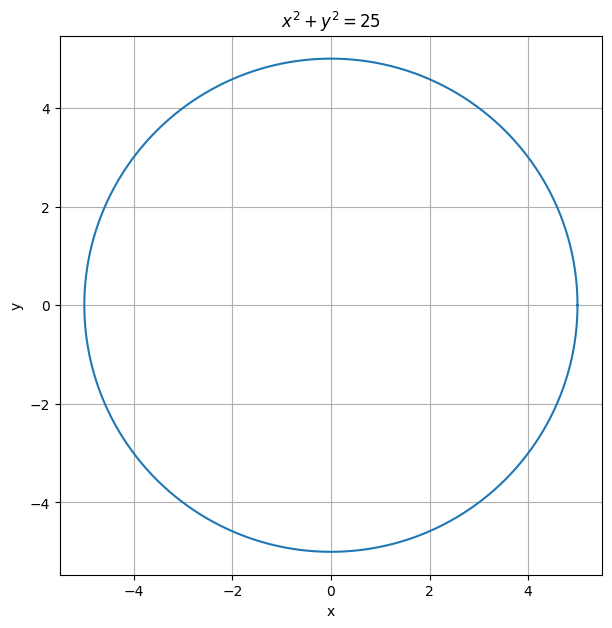

In [7]:
theta = np.linspace(0, 2*np.pi, 1000)

x = 5*np.cos(theta)
y = 5*np.sin(theta)

plt.figure(figsize=(7, 7))

plt.plot(x, y)

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$x^2+y^2=25$")
plt.grid(True)
plt.axis("equal")

plt.show()

# 6.3 Ejemplo más complicado

Considera:

$$
x^3+y^3=6xy
$$

Derivamos:

$$
3x^2+3y^2y'=6(xy'+y)
$$

Distribuimos:

$$
3x^2+3y^2y'=6xy'+6y
$$

Agrupamos términos con $(y')$:

$$
3y^2y'-6xy'=6y-3x^2
$$

$$
y'(3y^2-6x)=6y-3x^2
$$

Entonces:

$$
\boxed{
y'=
\frac{6y-3x^2}
{3y^2-6x}
}
$$

o:

$$
\boxed{
y'=
\frac{2y-x^2}
{y^2-2x}
}
$$

# 6.4 ¿Por qué importa en SciML?

Muchos sistemas físicos están definidos implícitamente:

$$
F(x,y,z)=0
$$

en lugar de:

$$
y=f(x)
$$

Esto aparece en:

* restricciones físicas;
* geometría;
* ecuaciones algebraicas;
* mecánica;
* fluidos;
* sistemas dinámicos.

# 7. DERIVADAS DE ORDEN SUPERIOR

La primera derivada:

$$
f'(x)
$$

La segunda:

$$
f''(x)
$$

La tercera:

$$
f'''(x)
$$

etc.

# 7.1 Ejemplo

$$
f(x)=x^5-3x^4+2x^2
$$

Primera:

$$
f'(x)=5x^4-12x^3+4x
$$

Segunda:

$$
f''(x)=20x^3-36x^2+4
$$

Tercera:

$$
f'''(x)=60x^2-72x
$$

Cuarta:

$$
f^{(4)}(x)=120x-72
$$

Quinta:

$$
f^{(5)}(x)=120
$$

# 7.2 Interpretación física

Si:

$$
x(t)
$$

es posición:

$$
x'(t)=v(t)
$$

$$
x''(t)=a(t)
$$

$$
x'''(t)
$$

se conoce como **jerk** en ingeniería: tasa de cambio de la aceleración.

# 7.3 Importancia en PDEs

Una ecuación física puede contener:

$$
\frac{\partial^2u}{\partial x^2}
$$

o incluso:

$$
\frac{\partial^4u}{\partial x^4}
$$

Por ejemplo, la ecuación de calor:

$$
\boxed{
\frac{\partial u}{\partial t}
=
\alpha
\frac{\partial^2u}{\partial x^2}
}
$$

Aquí aparece una segunda derivada espacial.

Esta ecuación será muy importante cuando avances hacia SciML.

# 8. TAYLOR

Aquí tenemos una de las herramientas más poderosas del cálculo.

Una función puede aproximarse localmente mediante un polinomio:

$$
f(x)
\approx
f(a)
+
f'(a)(x-a)
+
\frac{f''(a)}{2!}(x-a)^2
+\cdots
$$

La serie completa:

$$
\boxed{
f(x)=
\sum_{n=0}^{\infty}
\frac{f^{(n)}(a)}
{n!}(x-a)^n
}
$$

cuando se cumplen las condiciones correspondientes.

# 8.1 Ejemplo: $(e^x)$

Alrededor de $(a=0)$:

$$
e^x
=
1+x+
\frac{x^2}{2!}
+
\frac{x^3}{3!}
+\cdots
$$

# 8.2 Aproximaciones

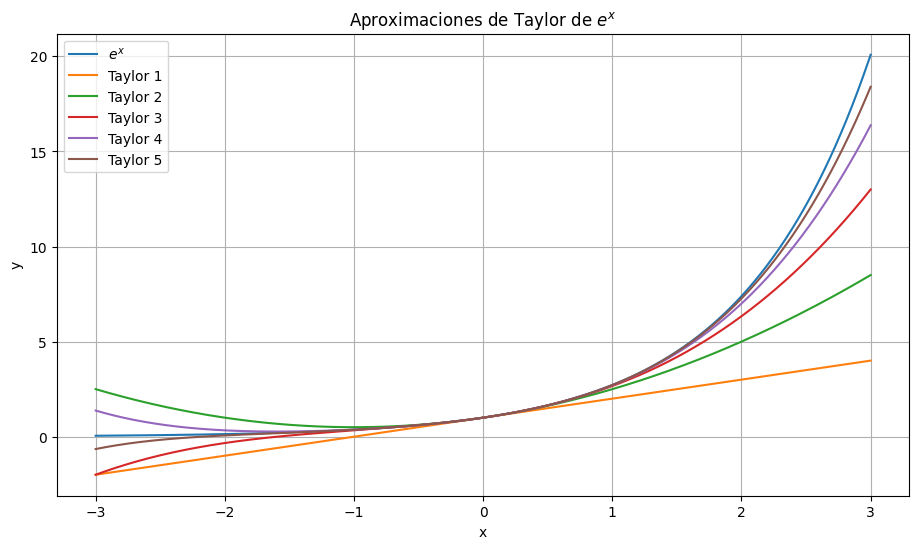

In [8]:
x = np.linspace(-3, 3, 1000)

exacta = np.exp(x)

T1 = 1 + x
T2 = 1 + x + x**2/2
T3 = T2 + x**3/6
T4 = T3 + x**4/24
T5 = T4 + x**5/120

plt.figure(figsize=(11, 6))

plt.plot(x, exacta, label=r"$e^x$")
plt.plot(x, T1, label="Taylor 1")
plt.plot(x, T2, label="Taylor 2")
plt.plot(x, T3, label="Taylor 3")
plt.plot(x, T4, label="Taylor 4")
plt.plot(x, T5, label="Taylor 5")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Aproximaciones de Taylor de $e^x$")
plt.grid(True)
plt.legend()

plt.show()

Observa algo importante:

> Taylor aproxima muy bien **cerca del punto de expansión**, pero la calidad puede deteriorarse lejos de él.

Esto será fundamental en métodos numéricos.

# 9. MACLAURIN

Maclaurin simplemente es Taylor alrededor de:

$$
a=0
$$

Entonces:

$$
\boxed{
f(x)=
f(0)
+
f'(0)x
+
\frac{f''(0)}{2!}x^2+\cdots
}
$$

# 9.1 Ejemplo: seno

$$
\sin x
=
x-\frac{x^3}{3!}
+\frac{x^5}{5!}
-\frac{x^7}{7!}
+\cdots
$$

# 9.2 Python

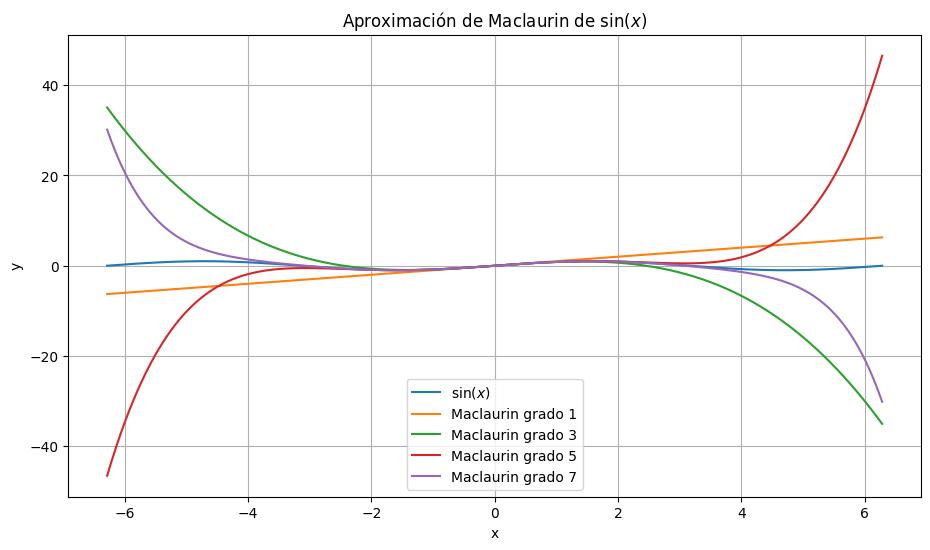

In [9]:
x = np.linspace(-2*np.pi, 2*np.pi, 2000)

exacta = np.sin(x)

M1 = x
M3 = x - x**3/6
M5 = M3 + x**5/120
M7 = M5 - x**7/5040

plt.figure(figsize=(11, 6))

plt.plot(x, exacta, label=r"$\sin(x)$")
plt.plot(x, M1, label="Maclaurin grado 1")
plt.plot(x, M3, label="Maclaurin grado 3")
plt.plot(x, M5, label="Maclaurin grado 5")
plt.plot(x, M7, label="Maclaurin grado 7")

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Aproximación de Maclaurin de $\sin(x)$")
plt.grid(True)
plt.legend()

plt.show()

# 9.3 Error de Taylor

Para SciML no basta con decir:

> "La aproximación funciona."

Hay que cuantificar el error.

Por ejemplo:

$$
E(x)=|f(x)-T_n(x)|
$$

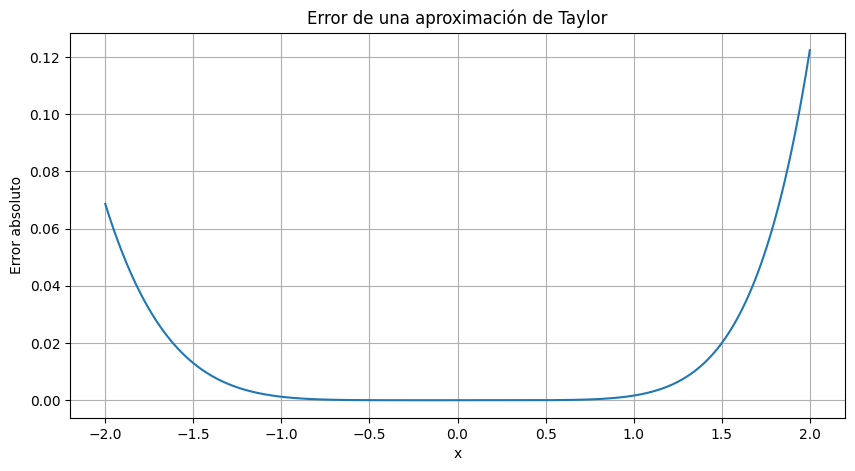

In [10]:
x = np.linspace(-2, 2, 1000)

exacta = np.exp(x)
T5 = (
    1 + x + x**2/2
    + x**3/6
    + x**4/24
    + x**5/120
)

error = np.abs(exacta - T5)

plt.figure(figsize=(10, 5))

plt.plot(x, error)

plt.xlabel("x")
plt.ylabel("Error absoluto")
plt.title("Error de una aproximación de Taylor")
plt.grid(True)

plt.show()

Este concepto de **error de aproximación** será central en métodos numéricos.

# 10. OPTIMIZACIÓN

Aquí empieza una conexión directa con Machine Learning.

La optimización busca encontrar:

$$
\boxed{\text{máximos o mínimos}}
$$

de una función.

# 10.1 Punto crítico

Si:

$$
f'(x)=0
$$

tenemos un candidato a máximo o mínimo.

Por ejemplo:

$$
f(x)=x^2-6x+5
$$

Derivamos:

$$
f'(x)=2x-6
$$

Igualamos:

$$
2x-6=0
$$

$$
x=3
$$

La segunda derivada:

$$
f''(x)=2>0
$$

por lo tanto tenemos un mínimo.

# 10.2 Python

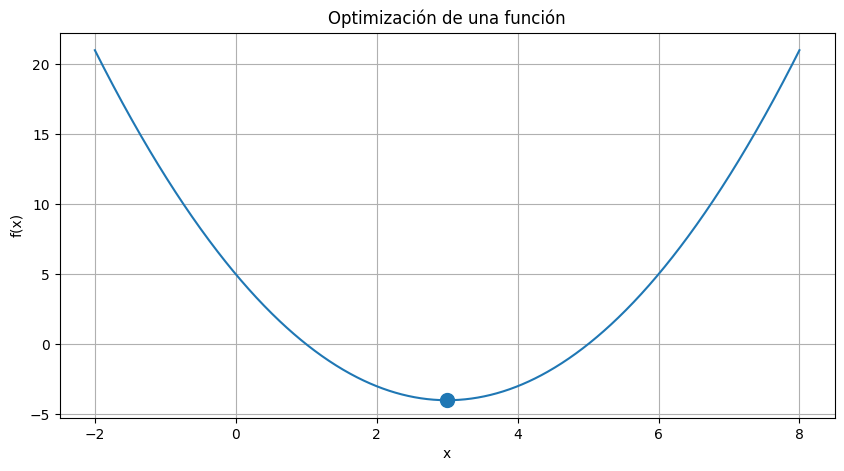

In [11]:
x = np.linspace(-2, 8, 1000)

f = x**2 - 6*x + 5

plt.figure(figsize=(10, 5))

plt.plot(x, f)
plt.scatter([3], [-4], s=100)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Optimización de una función")
plt.grid(True)

plt.show()

# 10.3 Ejemplo más difícil

Consideremos:

$$
f(x)=x^4-4x^3-7x^2+22x+24
$$

Derivamos:

$$
f'(x)=4x^3-12x^2-14x+22
$$

Ahora debemos resolver:

$$
4x^3-12x^2-14x+22=0
$$

Aquí podemos utilizar Python para encontrar los puntos críticos.

In [12]:
import sympy as sp

x = sp.symbols("x")

f = x**4 - 4*x**3 - 7*x**2 + 22*x + 24

df = sp.diff(f, x)

print("f(x) =", f)
print("f'(x) =", df)

critical_points = sp.solve(df, x)

print("Puntos críticos:")
print(critical_points)

f(x) = x**4 - 4*x**3 - 7*x**2 + 22*x + 24
f'(x) = 4*x**3 - 12*x**2 - 14*x + 22
Puntos críticos:
[1, 1 - sqrt(26)/2, 1 + sqrt(26)/2]


Después podemos clasificarlos mediante:

$$
f''(x)
$$

In [13]:
d2f = sp.diff(f, x, 2)

print("f''(x) =", d2f)

for point in critical_points:
    print(
        point,
        sp.N(f.subs(x, point)),
        sp.N(d2f.subs(x, point))
    )

f''(x) = 2*(6*x**2 - 12*x - 7)
1 36.0000000000000 -26.0000000000000
1 - sqrt(26)/2 -6.25000000000000 52.0000000000000
1 + sqrt(26)/2 -6.25000000000000 52.0000000000000


# 10.4 Optimización numérica

En aplicaciones reales, muchas veces no podemos resolver:

$$
f'(x)=0
$$

analíticamente.

Entonces usamos métodos numéricos.

Por ejemplo:

In [14]:
from scipy.optimize import minimize

def f(x):
    return x[0]**4 - 4*x[0]**3 - 7*x[0]**2 + 22*x[0] + 24

resultado = minimize(f, x0=[5])

print(resultado)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -6.249999999999986
        x: [ 3.550e+00]
      nit: 7
      jac: [-9.537e-07]
 hess_inv: [[ 1.923e-02]]
     nfev: 16
     njev: 8


Esto es una transición importante:

$$
\boxed{
\text{cálculo simbólico}
\rightarrow
\text{optimización numérica}
}
$$

# 11. EL CONCEPTO MÁS IMPORTANTE PARA MACHINE LEARNING

En una dimensión:

$$
f'(x)
$$

indica hacia dónde cambia la función.

En varias dimensiones tendremos:

$$
f(x_1,x_2,\ldots,x_n)
$$

y aparece el **gradiente**:

$$
\boxed{
\nabla f=
\begin{bmatrix}
\frac{\partial f}{\partial x_1}\\
\frac{\partial f}{\partial x_2}\\
\vdots\\
\frac{\partial f}{\partial x_n}
\end{bmatrix}
}
$$

El gradiente apunta en la dirección de máximo crecimiento local.

Para minimizar:

$$
f(\mathbf{x})
$$

podemos desplazarnos en dirección:

$$
-\nabla f
$$

Esto lleva directamente a:

$$
\boxed{
x_{k+1}
=
x_k-\eta\nabla f(x_k)
}
$$

que es **gradient descent**.

Y eso es fundamental en Machine Learning.

# 12. Ejemplo 2D de optimización

Considera:

$$
f(x,y)=x^2+2y^2
$$

El gradiente es:

$$
\nabla f=
\begin{bmatrix}
2x\\
4y
\end{bmatrix}
$$

El mínimo está en:

$$
(0,0)
$$

Podemos visualizar la superficie:

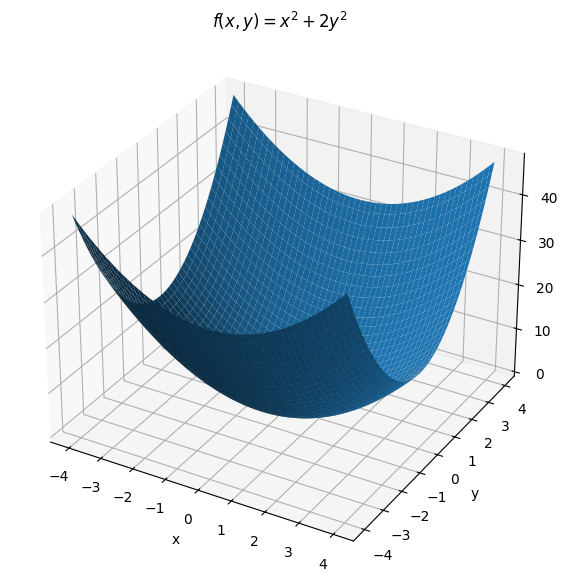

In [15]:
x = np.linspace(-4, 4, 200)
y = np.linspace(-4, 4, 200)

X, Y = np.meshgrid(x, y)

Z = X**2 + 2*Y**2

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, Y, Z)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x,y)")

ax.set_title(r"$f(x,y)=x^2+2y^2$")

plt.show()

# 12.1 Gradient descent visual

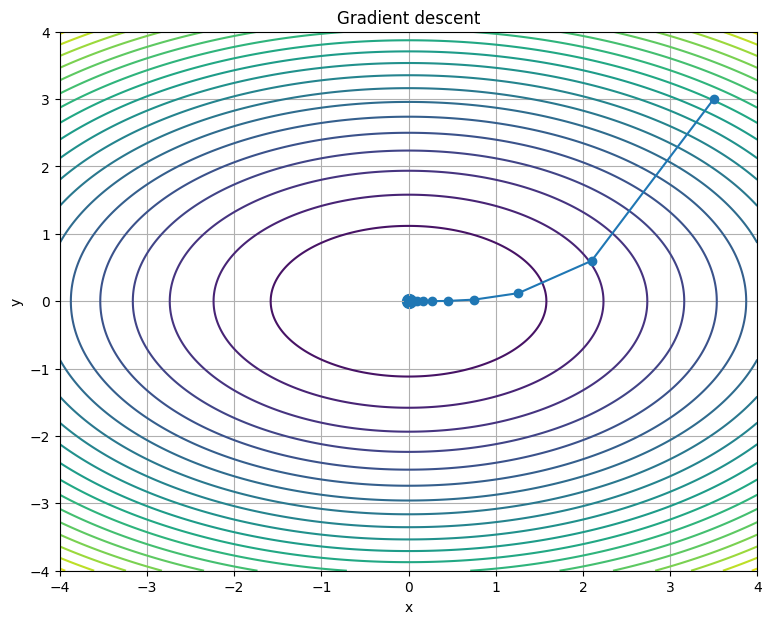

In [16]:
def f(x, y):
    return x**2 + 2*y**2

def gradient(x, y):
    return np.array([2*x, 4*y])

point = np.array([3.5, 3.0])

learning_rate = 0.2

trajectory = [point.copy()]

for _ in range(20):
    point = point - learning_rate * gradient(point[0], point[1])
    trajectory.append(point.copy())

trajectory = np.array(trajectory)

x = np.linspace(-4, 4, 300)
y = np.linspace(-4, 4, 300)

X, Y = np.meshgrid(x, y)
Z = f(X, Y)

plt.figure(figsize=(9, 7))

plt.contour(X, Y, Z, levels=20)

plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    marker="o"
)

plt.scatter([0], [0], s=100)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gradient descent")
plt.grid(True)

plt.show()

Esto es una conexión directa entre **cálculo diferencial y Machine Learning**.

# 13. Hessiano: el siguiente nivel

Cuando estudies derivadas de orden superior en varias variables, aparecerá la matriz Hessiana:

$$
\boxed{
H=
\begin{bmatrix}
\frac{\partial^2f}{\partial x_1^2}
&
\frac{\partial^2f}{\partial x_1\partial x_2}
\\
\frac{\partial^2f}{\partial x_2\partial x_1}
&
\frac{\partial^2f}{\partial x_2^2}
\end{bmatrix}
}
$$

Para:

$$
f(x,y)=x^2+2y^2
$$

tenemos:

$$
H=
\begin{bmatrix}
2&0\\
0&4
\end{bmatrix}
$$

El Hessiano contiene información sobre la **curvatura**.

Esto posteriormente conecta con:

* Newton;
* optimización;
* estabilidad;
* problemas inversos;
* entrenamiento de modelos;
* métodos numéricos.

# 14. Un ejemplo que junta TODO

Consideremos:

$$
f(x)=e^{-x^2}\cos(4x)
$$

Primero tenemos una función compuesta de:

$$
e^{-x^2}
$$

y:

$$
\cos(4x)
$$

La derivada:

$$
f'(x)
=
-2xe^{-x^2}\cos(4x)
-
4e^{-x^2}\sin(4x)
$$

Factorizando:

$$
\boxed{
f'(x)
=
e^{-x^2}
[-2x\cos(4x)-4\sin(4x)]
}
$$

Ahora podemos estudiar:

### Función

$$
f(x)
$$

### Primera derivada

$$
f'(x)
$$

### Segunda derivada

$$
f''(x)
$$

### Máximos/mínimos

$$
f'(x)=0
$$

### Curvatura

$$
f''(x)
$$

### Aproximación local

Taylor:

$$
f(x)\approx T_n(x)
$$

Todo esto constituye una especie de laboratorio de cálculo.

# 15. Ejemplo científico: temperatura

Supongamos que una barra tiene una temperatura:

$$
T(x)=100e^{-0.1x^2}
$$

La derivada:

$$
T'(x)
=
-0.2xe^{-0.1x^2}
$$

Esta nos dice cómo cambia la temperatura espacialmente.

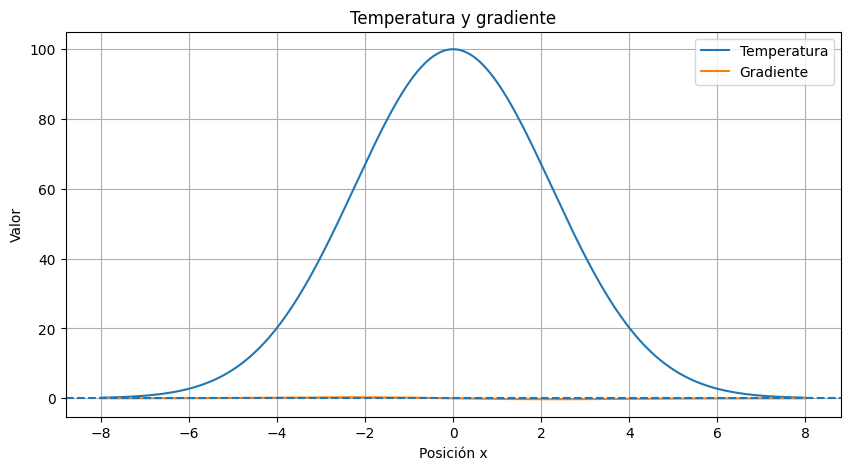

In [17]:
x = np.linspace(-8, 8, 1000)

T = 100*np.exp(-0.1*x**2)
dT = -0.2*x*np.exp(-0.1*x**2)

plt.figure(figsize=(10, 5))

plt.plot(x, T, label="Temperatura")
plt.plot(x, dT, label="Gradiente")

plt.axhline(0, linestyle="--")

plt.xlabel("Posición x")
plt.ylabel("Valor")
plt.title("Temperatura y gradiente")
plt.grid(True)
plt.legend()

plt.show()

Aquí la derivada ya tiene interpretación física.

# 16. Y esto te lleva a PDEs

Imagina ahora:

$$
T=T(x,t)
$$

en lugar de:

$$
T=T(x)
$$

Entonces tendremos:

$$
\frac{\partial T}{\partial x}
$$

y:

$$
\frac{\partial T}{\partial t}
$$

Y eventualmente:

$$
\frac{\partial^2T}{\partial x^2}
$$

La ecuación del calor:

$$
\boxed{
\frac{\partial T}{\partial t}
=
\alpha
\frac{\partial^2T}{\partial x^2}
}
$$

es uno de los ejemplos clásicos de ecuaciones diferenciales parciales.

Y en SciML aparecerá una idea muy importante:

> **la red neuronal no solamente aprende datos; puede utilizarse para aproximar soluciones de ecuaciones físicas.**

# 17. Mapa completo para tu camino a SciML

Ahora puedes ver por qué este bloque de cálculo es tan importante:

```text
LÍMITES
   │
   ▼
CONTINUIDAD
   │
   ▼
DERIVADAS
   │
   ├───────────────┐
   │               │
   ▼               ▼
GEOMETRÍA       FÍSICA
   │               │
   ▼               ▼
TANGENTES       VELOCIDAD
                   │
                   ▼
              ACELERACIÓN
                   │
                   ▼
          DERIVADAS SUPERIORES
                   │
                   ▼
              ECUACIONES
              DIFERENCIALES
```

Y paralelamente:

```text
DERIVADAS
    │
    ▼
REGLA DE LA CADENA
    │
    ▼
GRADIENTE
    │
    ▼
BACKPROPAGATION
    │
    ▼
MACHINE LEARNING
    │
    ▼
SCIENTIFIC MACHINE LEARNING
```

Y:

```text
DERIVADAS
    │
    ▼
TAYLOR / MACLAURIN
    │
    ▼
APROXIMACIÓN
    │
    ▼
MÉTODOS NUMÉRICOS
    │
    ▼
SIMULACIÓN
    │
    ▼
SCIENTIFIC MACHINE LEARNING
```

| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_1_Precalculo.ipynb) | [⏩](./1_3_Calculo_integral.ipynb) |